
LOG-NORMAL FIT RESULTS


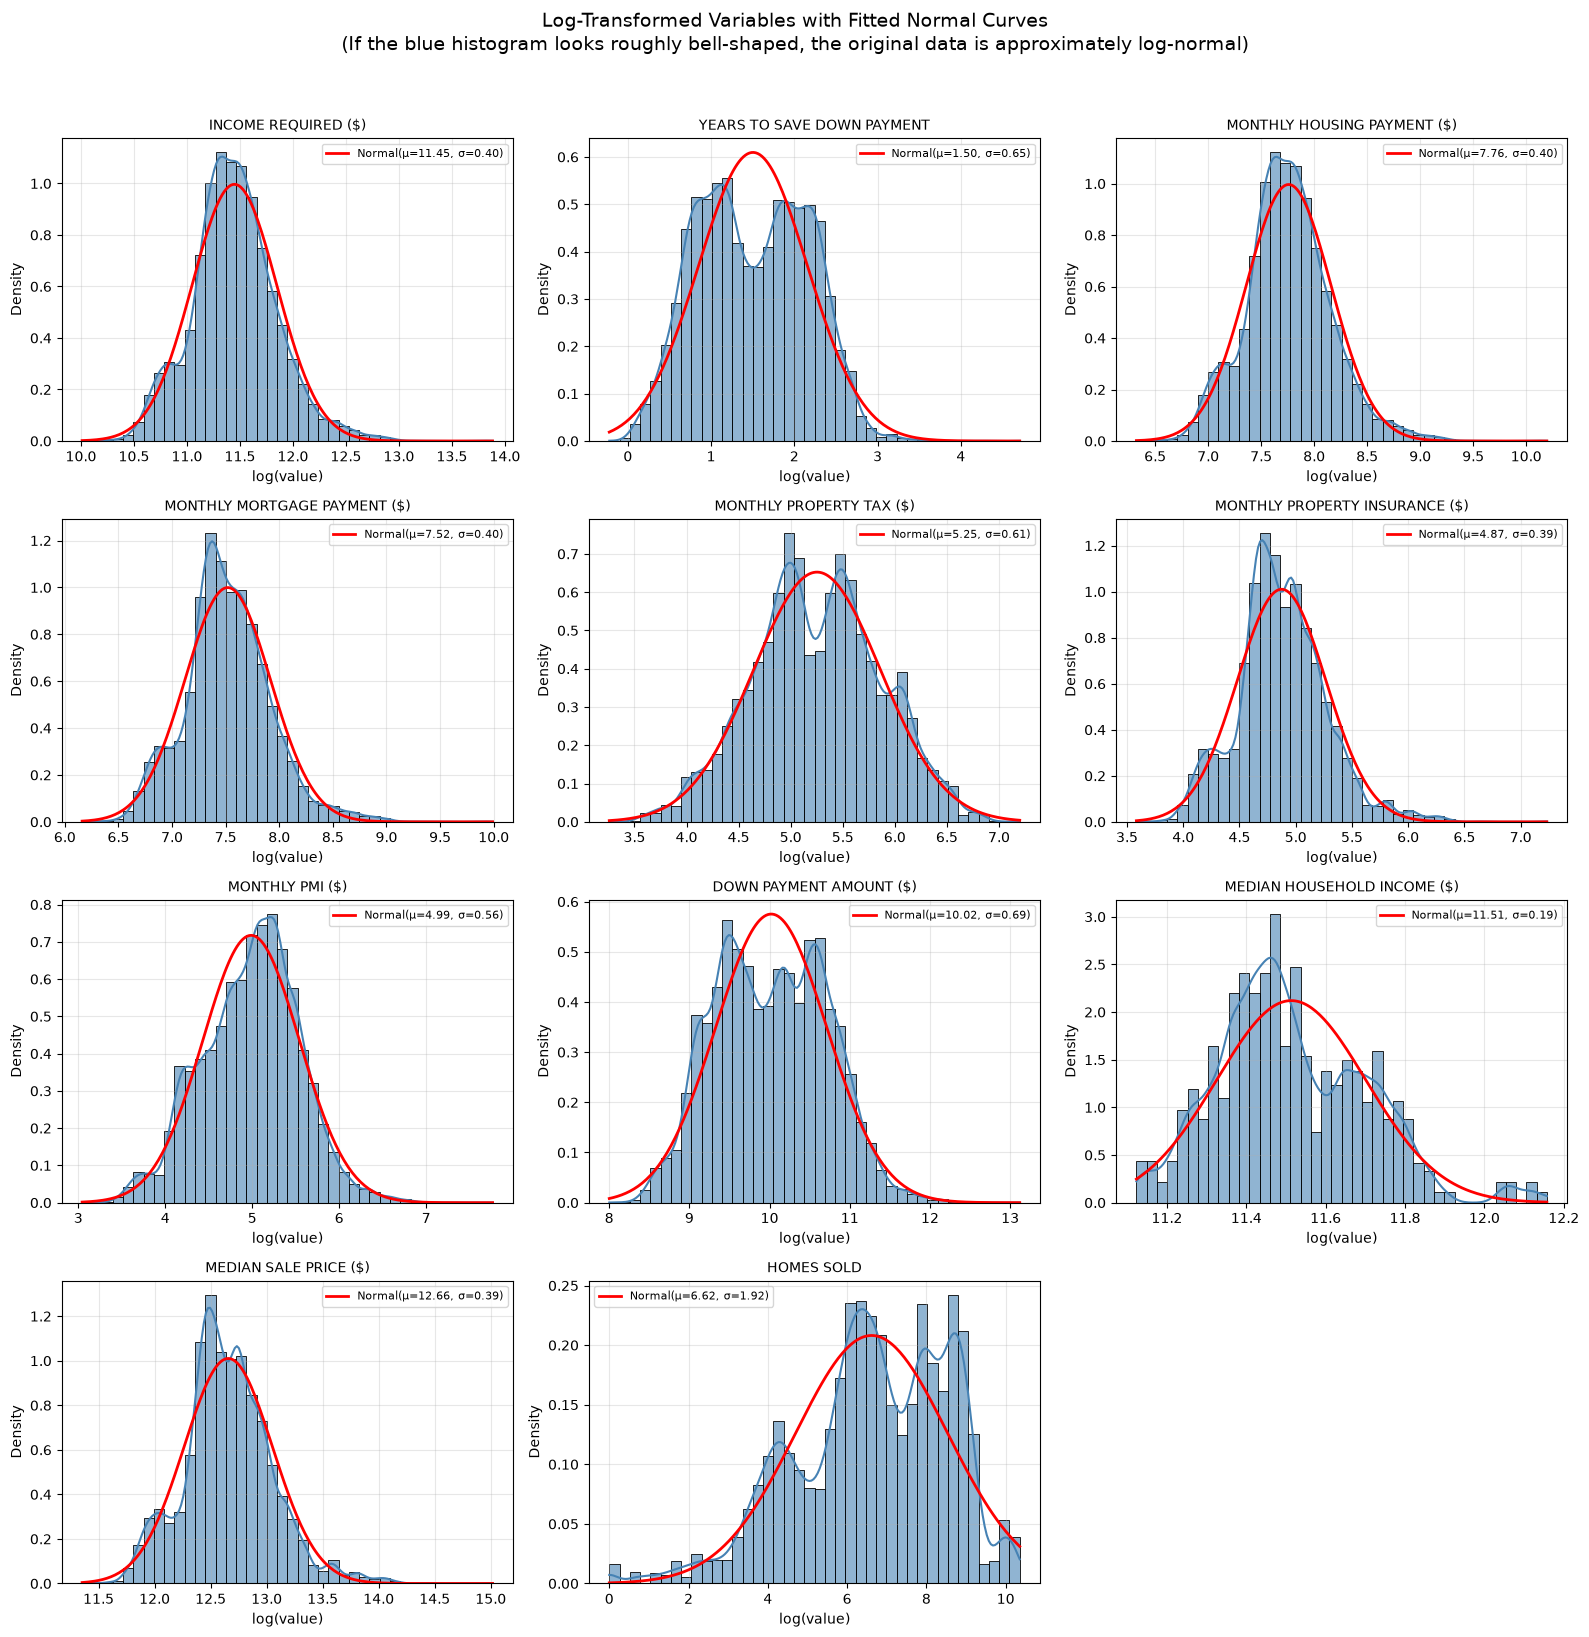

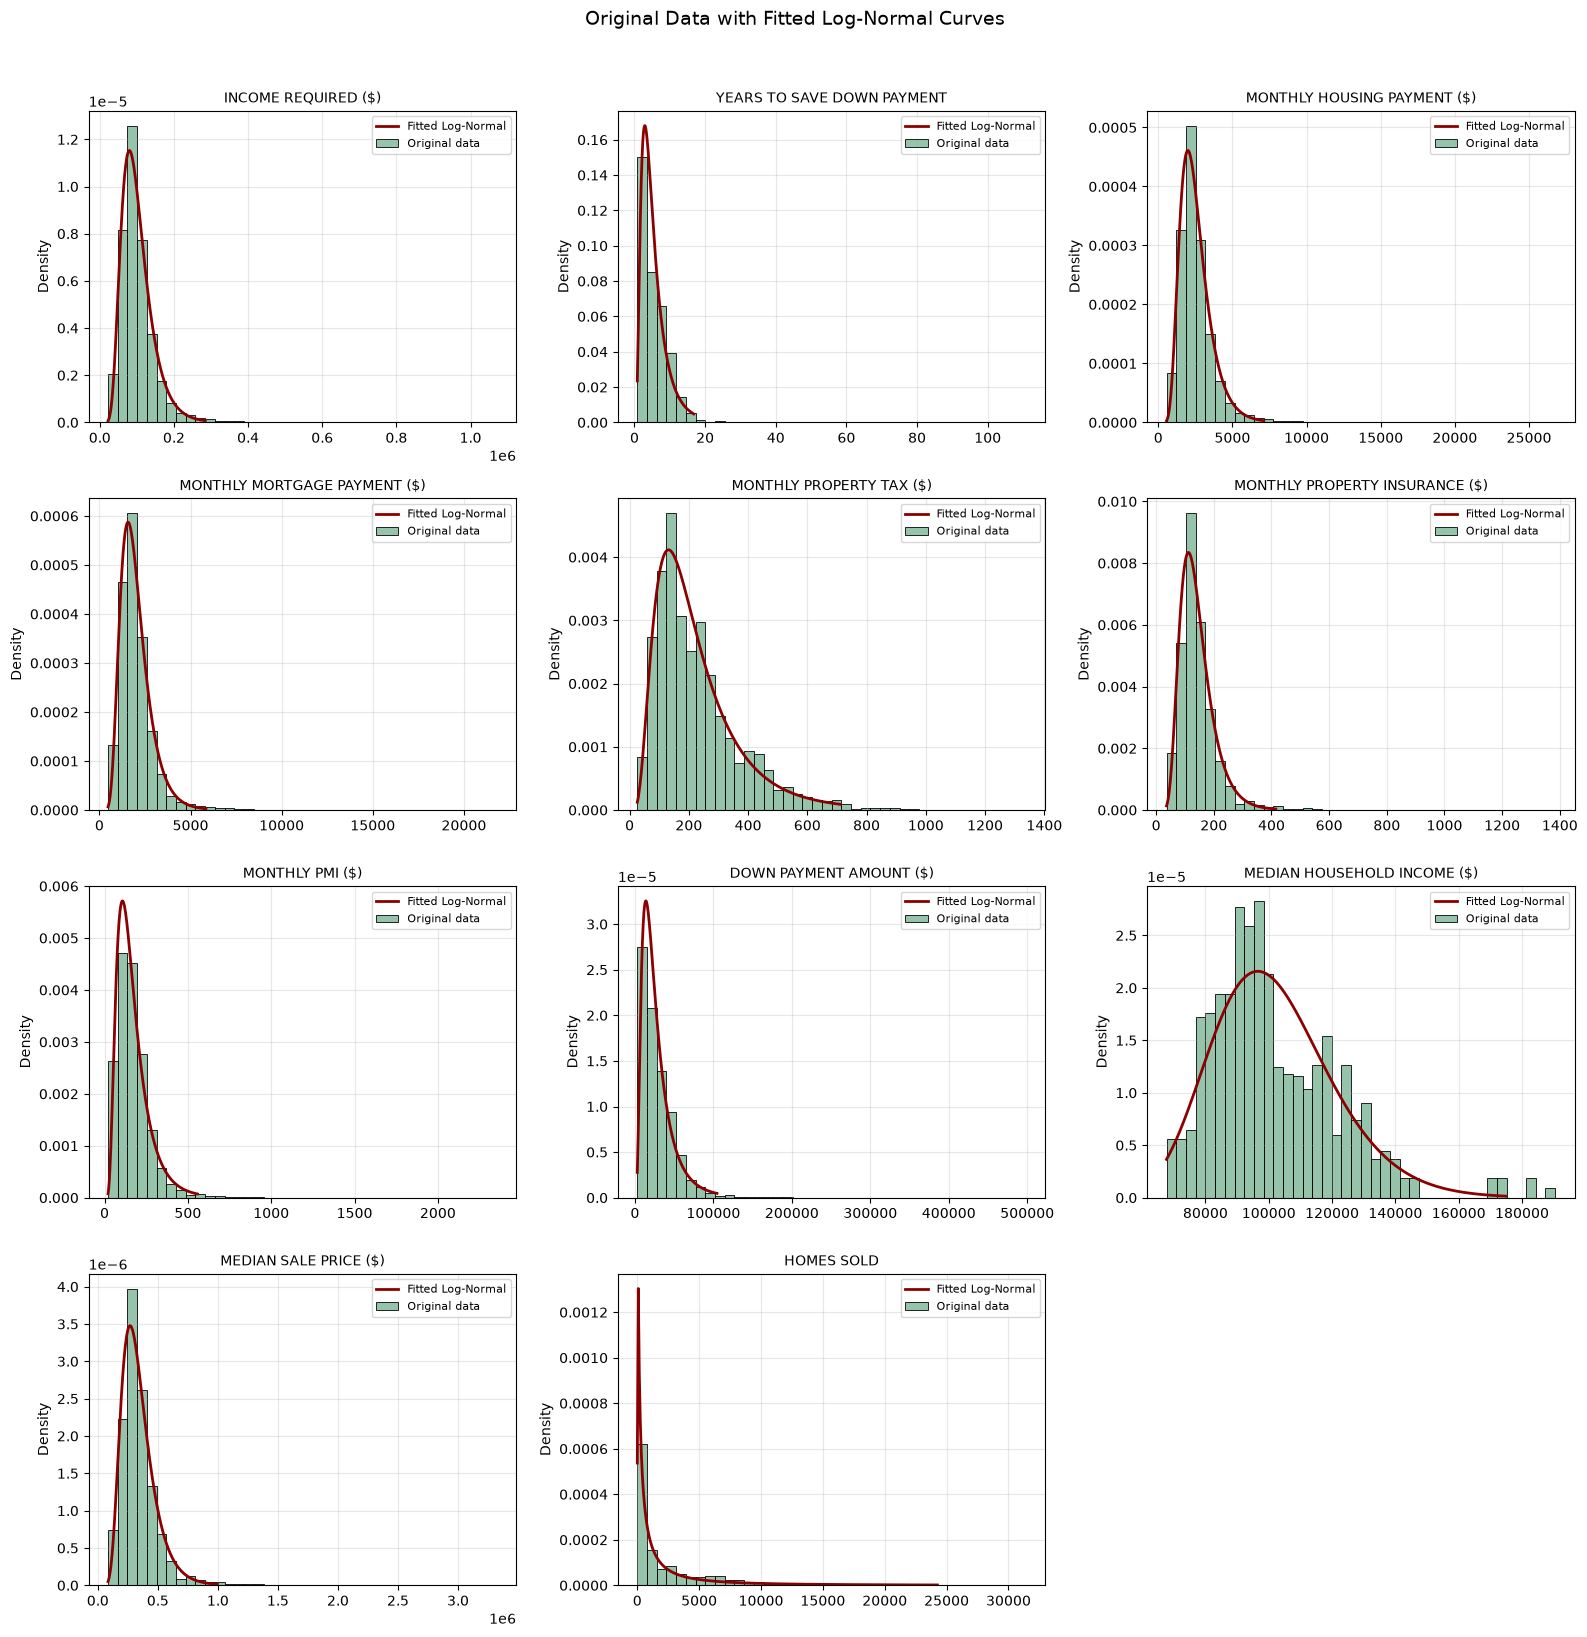

In [7]:
# ============================================================
# Log-Normal Distribution Analysis
# Variables: Income Required, Years to Save, Housing Payments,
# Down Payment, Incomes, Sale Price, Homes Sold
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


file_path = r"C:\Users\malee\OneDrive\Desktop\Team Project\HomeownerDatasetForModeling_FinalCopy.csv"

cols = [
    "INCOME REQUIRED ($)",
    "YEARS TO SAVE DOWN PAYMENT",
    "MONTHLY HOUSING PAYMENT ($)",
    "MONTHLY MORTGAGE PAYMENT ($)",
    "MONTHLY PROPERTY TAX ($)",
    "MONTHLY PROPERTY INSURANCE ($)",
    "MONTHLY PMI ($)",
    "DOWN PAYMENT AMOUNT ($)",
    "MEDIAN HOUSEHOLD INCOME ($)",
    "MEDIAN SALE PRICE ($)",
    "HOMES SOLD"
]

df = pd.read_csv(file_path, usecols=cols)


# ------------------------------------------------------------
# 2. Clean the data
#    - Drop rows with any missing values
#    - Keep only positive values (log of 0 or negative is undefined)
# ------------------------------------------------------------
df_clean = df.dropna()

# Filter out zeros and negatives for every column
for col in cols:
    df_clean = df_clean[df_clean[col] > 0]



# ------------------------------------------------------------
# 3. Log-transform and fit log-normal distribution
# ------------------------------------------------------------
results = {}

print("\n" + "="*70)
print("LOG-NORMAL FIT RESULTS")
print("="*70)

for col in cols:
    data = df_clean[col].values
    
    # Natural log transformation
    log_data = np.log(data)
    
    # Fit normal distribution to the logged data
    # the same as fitting a log-normal to the original data
    mu, sigma = stats.norm.fit(log_data)
    
    # Also get the classic log-normal parameters using scipy
    # shape = sigma, scale = exp(mu)
    shape, loc, scale = stats.lognorm.fit(data, floc=0)  # force loc=0 (common for money data)
    
    results[col] = {
        "mu": mu,
        "sigma": sigma,
        "lognorm_shape": shape,
        "lognorm_scale": scale,
        "n": len(data)
    }
    
 
# ------------------------------------------------------------
# 4. Visualization – one nice multi-panel figure
# ------------------------------------------------------------
n_vars = len(cols)
n_cols = 3
n_rows = int(np.ceil(n_vars / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols):
    ax = axes[i]
    data = df_clean[col].values
    log_data = np.log(data)
    
    # Histogram of the LOG-transformed data (should look roughly normal)
    sns.histplot(log_data, bins=40, kde=True, stat="density", 
                 color="steelblue", alpha=0.6, ax=ax)
    
    # Overlay the fitted normal curve
    mu = results[col]["mu"]
    sigma = results[col]["sigma"]
    x = np.linspace(log_data.min(), log_data.max(), 200)
    ax.plot(x, stats.norm.pdf(x, mu, sigma), "r-", lw=2, 
            label=f"Normal(μ={mu:.2f}, σ={sigma:.2f})")
    
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("log(value)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Log-Transformed Variables with Fitted Normal Curves\n"
             "(If the blue histogram looks roughly bell-shaped, the original data is approximately log-normal)",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Optional: Quick look at original-scale histograms + log-normal PDF
# ------------------------------------------------------------
fig2, axes2 = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes2 = axes2.flatten()

for i, col in enumerate(cols):
    ax = axes2[i]
    data = df_clean[col].values
    
    # Histogram of original data
    sns.histplot(data, bins=40, stat="density", color="seagreen", 
                 alpha=0.5, ax=ax, label="Original data")
    
    # Fitted log-normal PDF
    shape = results[col]["lognorm_shape"]
    scale = results[col]["lognorm_scale"]
    x = np.linspace(data.min(), np.percentile(data, 99), 300)  # avoid extreme tail
    ax.plot(x, stats.lognorm.pdf(x, shape, scale=scale), "darkred", lw=2,
            label="Fitted Log-Normal")
    
    ax.set_title(col, fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

for j in range(i + 1, len(axes2)):
    axes2[j].set_visible(False)

plt.suptitle("Original Data with Fitted Log-Normal Curves", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()
